# 2. Exploration

Descriptive statistics, distributions, chronological order and outliers. Nothing is tested here.
This part is to define what the future tests will be working with.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import experiment_data as data
import stats
import style

style.apply()
pd.set_option("display.precision", 3)
runs = data.load_runs()

## 2.1 Descriptive statistics per run-level variable

In [2]:
for variable, name in data.RUN_VARIABLES.items():
    print(name)
    display(stats.describe(runs, variable))

Total energy E (J)


,count,mean,median,std,var,min,max,iqr
strategy,,,,,,,,
S,30,76261.819,76277.947,202.394,40963.201,75837.281,76776.807,182.597
L,30,148634.798,148628.688,188.967,35708.359,148297.737,149245.477,198.921
R,30,137794.938,137759.220,234.950,55201.321,137261.303,138240.900,274.469


Energy per query E/N (J/query)


,count,mean,median,std,var,min,max,iqr
strategy,,,,,,,,
S,30,152.524,152.556,0.405,0.164,151.675,153.554,0.365
L,30,297.270,297.257,0.378,0.143,296.595,298.491,0.398
R,30,275.590,275.518,0.470,0.221,274.523,276.482,0.549


Energy per output token E/K (J/token)


...

,count,mean,median,std,var,min,max,iqr
strategy,,,,,,,,
S,30,85.018,85.031,0.101,0.01,84.741,85.246,0.103
L,30,0.000,0.000,0.000,0.00,0.000,0.000,0.000
R,30,20.079,20.088,0.099,0.01,19.907,20.253,0.150


Peak host memory (MiB)


,count,mean,median,std,var,min,max,iqr
strategy,,,,,,,,
S,30,12115.704,12121.279,32.443,1052.578,12040.488,12167.430,34.109
L,30,12127.212,12119.959,40.269,1621.590,12063.824,12217.449,43.157
R,30,19902.974,19885.348,47.411,2247.782,19827.379,20036.516,69.749


Peak GPU memory, both GPUs (MiB)


,count,mean,median,std,var,min,max,iqr
strategy,,,,,,,,
S,30,3372.0,3372.0,0.0,0.0,3372,3372,0.0
L,30,7378.0,7378.0,0.0,0.0,7378,7378,0.0
R,30,9838.0,9838.0,0.0,0.0,9838,9838,0.0


## 2.2 Distributions

Box plots with every run as a dot.

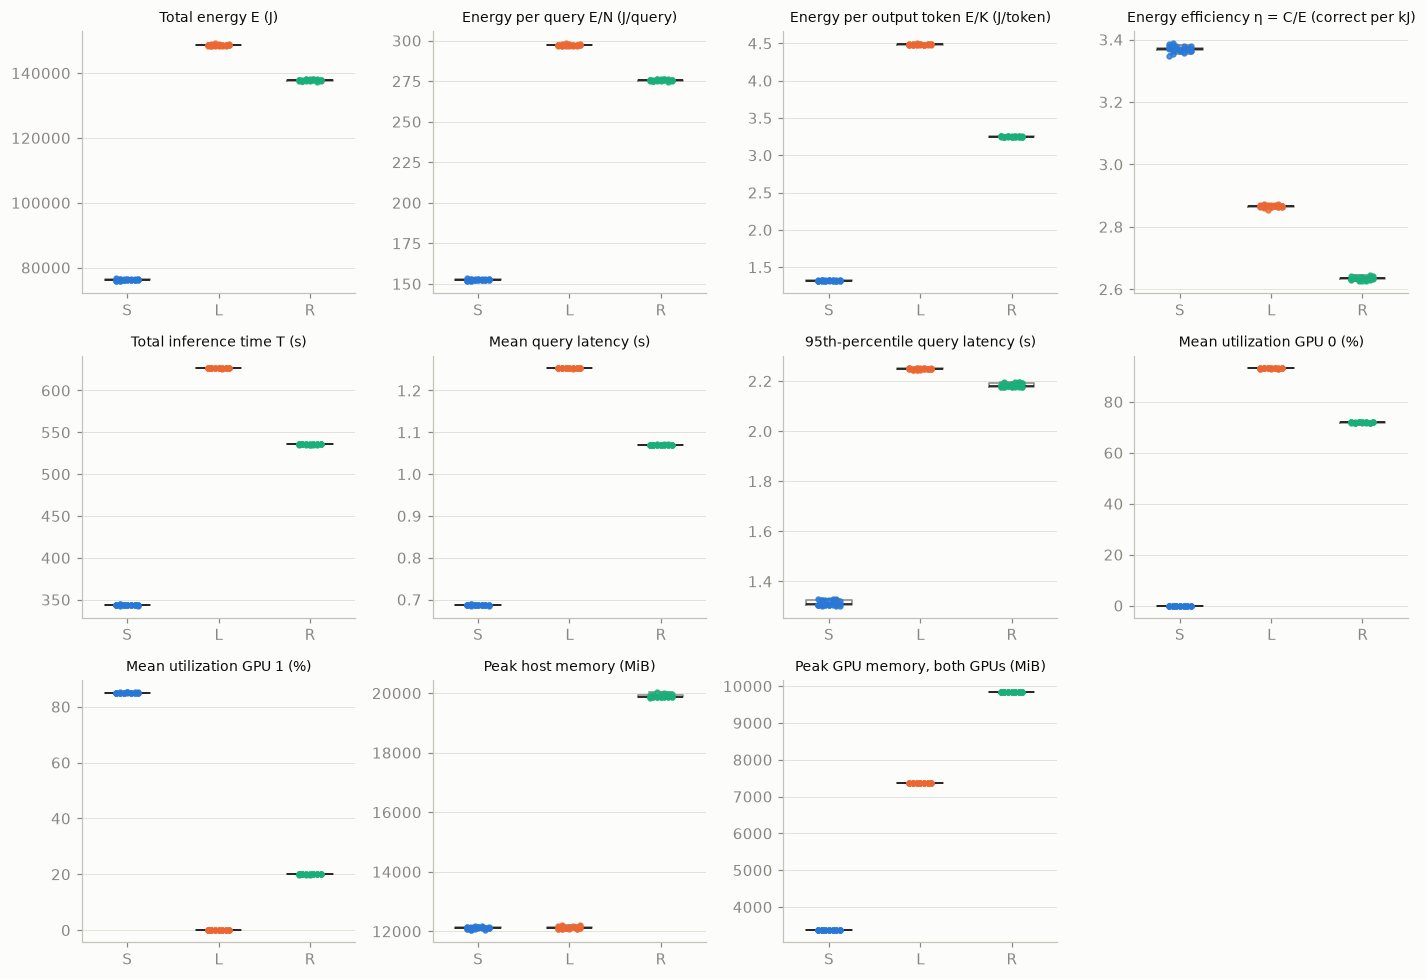

In [3]:
variables = list(data.RUN_VARIABLES)

fig, axes = plt.subplots(3, 4, figsize=(13, 9))

for ax, variable in zip(axes.flat, variables):
    values = [runs.loc[runs["strategy"] == s, variable] for s in data.STRATEGIES]
    ax.boxplot(values, tick_labels=data.STRATEGIES, widths=0.5, showfliers=False,
               medianprops={"color": style.INK}, boxprops={"color": style.MUTED},
               whiskerprops={"color": style.MUTED}, capprops={"color": style.MUTED})
    for i, (strategy, v) in enumerate(zip(data.STRATEGIES, values), start=1):
        jitter = (pd.Series(range(len(v))) % 7 - 3) * 0.04
        ax.scatter(i + jitter, v, s=10, color=style.COLORS[strategy], alpha=0.8, zorder=3)
        
    ax.set_title(data.RUN_VARIABLES[variable], fontsize=9)
    ax.grid(axis="x", visible=False)
    
axes.flat[-1].axis("off")
plt.tight_layout()

## 2.3 Chronological order and temporal dependence

The tests assume independent runs. Remove each strategy's mean and look for trends/autocorrelation.
The variable shown is energy per query. The other energy variables are proportional because
N and K are constants for each strategy. (as discussed in the report)

S: Spearman rho(order, energy per query) = -0.38, p = 0.036
L: Spearman rho(order, energy per query) = -0.07, p = 0.718
R: Spearman rho(order, energy per query) = -0.12, p = 0.545




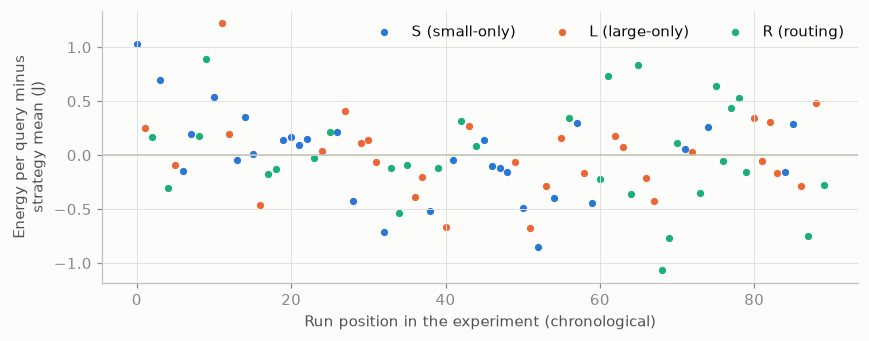

In [4]:
runs["residual_energy_per_query_j"] = (runs["energy_per_query_j"] - runs.groupby("strategy", observed=True)["energy_per_query_j"].transform("mean"))

fig, ax = plt.subplots(figsize=(8, 3.2))

for strategy in data.STRATEGIES:
    subset = runs[runs["strategy"] == strategy]
    ax.scatter(subset["order"], subset["residual_energy_per_query_j"], s=14,
               color=style.COLORS[strategy], label=style.label(strategy))
    
ax.axhline(0, color=style.AXIS, linewidth=1)
ax.set_xlabel("Run position in the experiment (chronological)")
ax.set_ylabel("Energy per query minus\nstrategy mean (J)")
ax.legend(ncols=3, loc="upper right")

plt.tight_layout()

from scipy.stats import spearmanr
for strategy in data.STRATEGIES:
    subset = runs[runs["strategy"] == strategy]
    rho, p = spearmanr(subset["order"], subset["energy_per_query_j"])
    print(f"{strategy}: Spearman rho(order, energy per query) = {rho:+.2f}, p = {p:.3f}")
print("\n")

**Autocorrelation** of the residuals in chronological order, with a Ljung-Box test. A small
p-value means that neighbouring runs resemble each other more than independence allows for.

,lb_stat,lb_pvalue
1,8.036,0.005
5,13.239,0.021
10,16.472,0.087


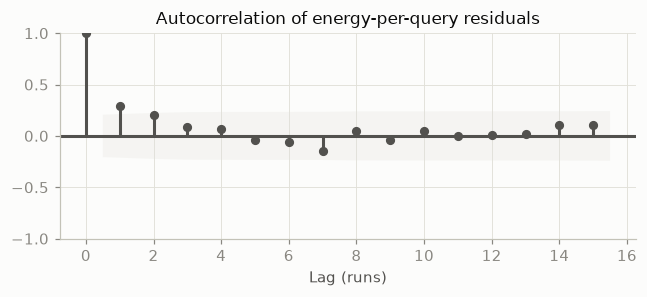

In [5]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

residuals = runs.sort_values("order")["residual_energy_per_query_j"]

# These residuals mix all three strategies so they're gray.
fig, ax = plt.subplots(figsize=(6, 2.8))
plot_acf(residuals, lags=15, ax=ax, color=style.SECONDARY, vlines_kwargs={"colors": style.SECONDARY})

for band in ax.collections[1:]:
    band.set_facecolor(style.GRID)
    
ax.set_title("Autocorrelation of energy-per-query residuals")
ax.set_xlabel("Lag (runs)")

plt.tight_layout()
acorr_ljungbox(residuals, lags=[1, 5, 10])

**GPU temperature at the start of each run.**

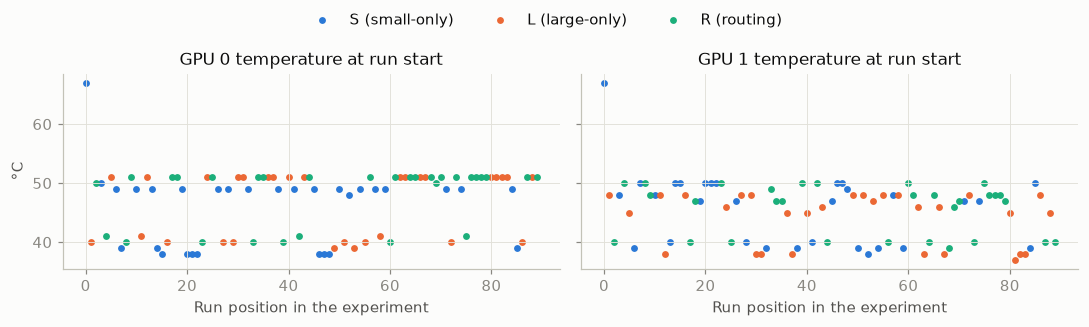

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, gpu in zip(axes, (0, 1)):
    for strategy in data.STRATEGIES:
        subset = runs[runs["strategy"] == strategy]
        ax.scatter(subset["order"], subset[f"gpu{gpu}_start_temp_c"], s=12,
                   color=style.COLORS[strategy], label=style.label(strategy))
    ax.set_title(f"GPU {gpu} temperature at run start")
    ax.set_xlabel("Run position in the experiment")
axes[0].set_ylabel("°C")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncols=3, loc="upper center")
plt.tight_layout(rect=(0, 0, 1, 0.9))

## 2.4 Outliers

Runs more than 3 standard deviations from their strategy's mean for a given variable.
From the report, outliers stay in the data except if they come from a measuring error.

In [7]:
flagged = []

for variable in data.RUN_VARIABLES:
    grouped = runs.groupby("strategy", observed=True)[variable]
    z = (runs[variable] - grouped.transform("mean")) / grouped.transform("std")
    for index in z[z.abs() > 3].index:
        flagged.append({"variable": variable, "run_id": runs.at[index, "run_id"],
                        "order": runs.at[index, "order"], "z": z[index]})
        
pd.DataFrame(flagged)

,variable,run_id,order,z
0,energy_j,run_1_repetition_2,11,3.232
1,energy_per_query_j,run_1_repetition_2,11,3.232
2,energy_per_token_j,run_1_repetition_2,11,3.232
3,efficiency_correct_per_kj,run_1_repetition_2,11,-3.223


**Notes**

- **Spread is small.** Within a strategy, energy varies by only 0.1–0.3% (coefficient of variation),
  while the strategies differ by up to 2 times. Practically any test will be significant (notebook 3), so
  effect sizes and practical differences matter more than p-values.
- **The first run is a hot start, but not an outlier.** Run 0 of the experiment (a small-only run)
  started at 67 °C on both GPUs; every other run started at 37–51 °C. Its energy is 2.5 standard
  deviations above the other small-only runs, below the outlier threshold.
  - Cause: it began right after the 5-minute warm-up, which is not followed by the 60 s cool-down
    that every other run gets.
  - Notebook 3 includes a sensitivity check without it.
  - For a future run: add a cool-down after the warm-up.
- **One statistical outlier:** a large-only run (order 11) with |z| = 3.2, only 0.4% above the
  large-only mean. It isn't a measurement error, so per the report it stays.
- **The cool-down leaves heat behind.** A GPU starts about 10 °C warmer after a run that used it
  (GPU 0: 50 °C after L or R, 40 °C after S; GPU 1: 49 °C after S, 39 °C after L). The shuffled
  order spreads this over all strategies, but it belongs under threats to validity.
- **Drift.**
  - S energy goes down over the experiment (Spearman ρ = −0.38, p = 0.036). L and R show no
    significant trend (ρ = −0.07 and −0.12).
  - The start temperatures show no strong trend either (ρ = ±0.24).
- **Autocorrelation.** Ljung-Box finds it at lag 1 (p = 0.005) and lag 5 (p = 0.02), but
  not at lag 10. Adjacent runs aren't fully independent. The run order was shuffled,
  so this correlation is spread out over all strategies, but it belongs under threats to validity.